# Tokopedia Recovery 2027 — Monte Carlo Strategy Simulation

**Our recommendation:** *Choose confidently. Organize your shopping. Restock reliably.*
Planned Comparers × Electronics and Routine Households × FMCG, delivered through three pillars plus selective value support. **No dedicated reseller program.**

| Part | Question it answers |
|---|---|
| **0** | How the simulation works, in plain words |
| **1** | What happens if we chase *other* buyers with *other* strategies? (expected value, P(success), P(loss)) |
| **2** | How does **our** strategy perform, and which pillar does the work? |
| **3** | Should we add a reseller program to our strategy? (OURS vs OURS + Reseller) |
| **4** | Law of large numbers: do the averages converge, and is the improvement real or just noise? |
| **5** | Recovery path for 2027–2029 (buyers, orders, GMV) |
| **6** | Stress tests, assumptions, and references |

> All case figures are **fictional case data** (USD 1 = IDR 16,000). Effect sizes are **scenario assumptions**, each tied to a case exhibit and, where possible, to published research (see references). The simulation **compares strategies under consistent assumptions**. It is not a forecast.

## 0. How the simulation works (plain words)

For every one of thousands of "possible 2027s":

1. **Do-nothing world.** Buyers and orders per buyer keep falling at the 2025→2026 pace, with some randomness.
2. **Strategy world.** Each **lever** (for example "Choose confidently") is drawn at random:
   - Did it work? It succeeds with probability `p_work`; if it flops, only 0–30% of its effect shows up, and its cost is **still paid**.
   - How big was the effect? Drawn from a *(low, likely, high)* range for **% more buyers**, **% more orders per buyer**, and **% basket size**.
   - Who is affected? The lever's **weights**: 1.0 means the target archetype; 0.3 means a 30% spill-over to others.
3. **Money.** Extra GMV × archetype margin, minus extra vouchers, minus programme cost, minus any GMV simply stolen from TikTok Shop (*cannibalization*, valued at the 7.1% margin).
4. Repeat for 3 years (2027–2029). Product capabilities keep working, while voucher effects fade every year.

```
Orders = Buyers × Orders per buyer        GMV = Orders × AOV        Contribution = GMV × margin
Net value = Δ Contribution − extra subsidy − programme cost − TikTok Shop cannibalization
```

**Success** = the strategy **pays for itself over 2027–29** *and* **adds active buyers in 2027**.
**Stretch success** = success *and* at least **+0.5m buyers** (1/6 of the 3m lost since 2024).

## 0.1 Setup and case data (Exhibits 1, 2A, 2B, 3A, 3B)

In [1]:
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
PINK, CYAN, GREY, DARK, TEAL = "#FE2C55", "#25F4EE", "#9AA0A6", "#161823", "#0FA3A3"

N_SIMS = 10_000
SEED = 2027
YEARS = [2027, 2028, 2029]
PORTFOLIO_MARGIN = 0.071

# Exhibit 1: company trajectory
hist = pd.DataFrame({
    "active_buyers_m": [30.0, 29.0, 27.0],
    "orders_m": [232, 220, 198],
    "gmv_bn": [4.121875, 3.925625, 3.585],
}, index=[2024, 2025, 2026])
hist["orders_per_buyer"] = hist.orders_m / hist.active_buyers_m
hist["aov_usd"] = hist.gmv_bn * 1000 / hist.orders_m

# Order-decline bridge (calculation B3): buyer-count vs frequency
f24, f26 = 232 / 30, 198 / 27
bridge_buyers, bridge_freq = (27 - 30) * f24, 27 * (f26 - f24)
print(f"Orders 232m -> 198m (-34m): buyer-count component {bridge_buyers:.1f}m ({bridge_buyers/-34:.0%}), "
      f"frequency component {bridge_freq:.1f}m ({bridge_freq/-34:.0%})")
hist

Orders 232m -> 198m (-34m): buyer-count component -23.2m (68%), frequency component -10.8m (32%)


,active_buyers_m,orders_m,gmv_bn,orders_per_buyer,aov_usd
2024,30.00,232,4.12,7.73,17.77
2025,29.00,220,3.93,7.59,17.84
2026,27.00,198,3.58,7.33,18.11


In [2]:
# Exhibit 2A + 2B + 3A: 2026 archetypes (mutually exclusive)
seg = pd.DataFrame({
    "buyer_share": [0.289, 0.263, 0.222, 0.185, 0.041],
    "orders_m":    [52, 50, 55, 29, 12],
    "aov_usd":     [15.88, 17.94, 10.44, 22.25, 53.75],
    "margin":      [0.065, 0.088, 0.072, 0.089, 0.038],
    "repeat_90d":  [0.26, 0.42, 0.58, 0.34, 0.38],
    "price_sens":  [0.72, 0.38, 0.31, 0.29, 0.64],
    "promo_sens":  [0.58, 0.36, 0.34, 0.32, 0.68],
}, index=["Price-led", "Planned Comparers", "Routine Households", "Trend & Brand", "Reseller"])
seg["buyers_m"] = seg.buyer_share * hist.loc[2026, "active_buyers_m"]
seg["orders_per_buyer"] = seg.orders_m / seg.buyers_m
seg["gmv_m"] = seg.orders_m * seg.aov_usd
seg["contribution_m"] = seg.gmv_m * seg.margin
SEGS = list(seg.index)

# Exhibit 3A: lead journeys inside our two archetypes
matrix = pd.DataFrame({"Electronics": [7, 14, 3, 6, 5], "FMCG": [17, 9, 25, 1, 1]}, index=SEGS)
print(f"GMV check {seg.gmv_m.sum()/1000:.3f}bn vs 3.585bn | contribution {seg.contribution_m.sum():.1f}m")
print(f"Our archetypes: {seg.loc[['Planned Comparers','Routine Households'],'buyer_share'].sum():.1%} of buyers, "
      f"{seg.loc[['Planned Comparers','Routine Households'],'orders_m'].sum()/198:.1%} of orders | lead journeys "
      f"Comparers×Electronics {matrix.loc['Planned Comparers','Electronics']}m + Households×FMCG "
      f"{matrix.loc['Routine Households','FMCG']}m = {(14+25)/198:.1%} of orders")
seg[["buyers_m", "orders_m", "orders_per_buyer", "aov_usd", "gmv_m", "margin", "contribution_m", "repeat_90d", "price_sens"]]

GMV check 3.587bn vs 3.585bn | contribution 255.9m
Our archetypes: 48.5% of buyers, 53.0% of orders | lead journeys Comparers×Electronics 14m + Households×FMCG 25m = 19.7% of orders


,buyers_m,orders_m,orders_per_buyer,aov_usd,gmv_m,margin,contribution_m,repeat_90d,price_sens
Price-led,7.80,52,6.66,15.88,825.76,0.07,53.67,0.26,0.72
Planned Comparers,7.10,50,7.04,17.94,897.00,0.09,78.94,0.42,0.38
Routine Households,5.99,55,9.18,10.44,574.20,0.07,41.34,0.58,0.31
Trend & Brand,5.00,29,5.81,22.25,645.25,0.09,57.43,0.34,0.29
Reseller,1.11,12,10.84,53.75,645.00,0.04,24.51,0.38,0.64


## 0.2 Levers: the building blocks of every strategy

Each strategy is a **bundle of levers**. Ranges are `(low, likely, high)` in %. `subsidy_pp` is paid on **all** GMV of the affected buyers, because vouchers also get used on orders that would have happened anyway. That is the well-known subsidy leakage (Gupta, 1988; Pauwels et al., 2002).

In [3]:
LEVERS = {
    # OUR STRATEGY: the three deck pillars plus selective value
    "P1 Attract through trust": dict(
        weights={"Planned Comparers": 1.0, "Routine Households": 0.5, "Trend & Brand": 0.3, "Price-led": 0.2, "Reseller": 0.2},
        buyer=(1.0, 2.5, 4.0), freq=(0.0, 0.5, 1.0), aov=(0, 0, 0), subsidy_pp=(0, 0, 0),
        fixed=(3.0, 4.5, 7.0), p_work=0.75,
        what="Mall/official-store & brand entry points, verified status + warranty, Clear Protection & Order Support, "
             "focused campaign deep-linking into the journey",
        evidence="E5 trust 3.7 = smallest gap (0.5); E4 trust/after-sales issues 11%→19%; Electronics trust-sensitive (E3B)",
        literature="Reichheld & Sasser (1990): retention economics; Gupta, Lehmann & Stuart (2004): customer value"),
    "P2 Choose confidently": dict(
        weights={"Planned Comparers": 1.0, "Trend & Brand": 0.3, "Price-led": 0.3, "Reseller": 0.3, "Routine Households": 0.2},
        buyer=(1.5, 3.0, 5.0), freq=(1.0, 2.0, 3.5), aov=(0.0, 1.0, 2.0), subsidy_pp=(0, 0, 0),
        fixed=(2.0, 3.0, 5.0), p_work=0.80,
        what="Category → subcategory → brand navigation, product-only comparison of up to 3 products, Rencana Beli saved shortlist",
        evidence="E4 search/navigation issues 16%→26%; E2B Comparers' risk = leakage before checkout; 14m Comparer×Electronics orders",
        literature="Häubl & Trifts (2000): comparison matrices cut search effort, improve decisions; Iyengar & Lepper (2000): choice overload"),
    "P3 Buy & restock reliably": dict(
        weights={"Routine Households": 1.0, "Planned Comparers": 0.4, "Price-led": 0.2, "Trend & Brand": 0.1, "Reseller": 0.1},
        buyer=(1.0, 2.5, 4.0), freq=(2.0, 4.0, 6.5), aov=(0, 0, 0), subsidy_pp=(0, 0, 0),
        fixed=(2.0, 3.5, 5.5), p_work=0.75,
        what="Belanja Saya / Belanja Rutin, Stock-Checked Baskets, customer-approved alternatives, reminders",
        evidence="E4 unavailable/choice issues 18%→29%; E2B Households 58% repeat, 72% predictable, risk = stock-outs break habit; 25m Household×FMCG orders",
        literature="Corsten & Gruen (2003): at a stock-out ~31% of shoppers buy elsewhere and ~9% don't buy at all"),
    "V Targeted value & shipping": dict(
        weights={"Planned Comparers": 1.0, "Routine Households": 1.0},
        buyer=(0.5, 1.5, 3.0), freq=(0.5, 1.0, 2.0), aov=(0, 0, 0), subsidy_pp=(0.05, 0.15, 0.30),
        fixed=(0.3, 0.5, 1.0), p_work=0.90,
        what="Selective first-purchase / replenishment / shipping support for named needs, merchant co-funded where possible",
        evidence="E4 price issues 33%, but our archetypes are only 38%/31% price-sensitive (vs 72% Price-led)",
        literature="Pauwels, Hanssens & Siddarth (2002): promotion effects rarely persist, so keep it small and targeted"),

    # ALTERNATIVES
    "A Broad vouchers for Price-led": dict(
        weights={"Price-led": 1.0, "Trend & Brand": 0.1},
        buyer=(4, 8, 12), freq=(3, 5, 8), aov=(-3, -1, 0), subsidy_pp=(2.0, 3.0, 4.5),
        fixed=(1, 2, 4), p_work=0.90,
        what="Platform-funded vouchers / free shipping to win the price-led battle",
        evidence="E2B Price-led 72% price / 58% promo sensitive, 26% repeat; E5 Competitor A leads price 4.2 vs 3.6",
        literature="Gupta (1988): ~84% of promo sales lift is brand switching; Mela, Gupta & Lehmann (1997): promos raise price sensitivity"),
    "C Creator/content push vs Comp. B": dict(
        weights={"Trend & Brand": 1.0, "Price-led": 0.05, "Planned Comparers": 0.05},
        buyer=(2, 6, 12), freq=(0, 2, 5), aov=(0, 0, 2), subsidy_pp=(0.5, 1.0, 2.0),
        fixed=(12, 20, 35), p_work=0.50,
        what="Creator commissions and content production to win Trend & Brand Seekers",
        evidence="E5 Competitor B discovery 4.6 vs 3.0 (largest gap); same audience as TikTok Shop",
        literature="—"),
    "D Fix delivery for everyone": dict(
        weights={s: 1.0 for s in SEGS},
        buyer=(1, 2.5, 4.5), freq=(1, 2, 3), aov=(0, 0, 0), subsidy_pp=(0.3, 0.6, 1.0),
        fixed=(35, 55, 85), p_work=0.60,
        what="Broad logistics and service upgrade",
        evidence="E4 delivery issues 14%→25%; E5 reliability 3.2 vs A 4.3",
        literature="—"),
    "R Reseller program": dict(
        kind="reseller", weights={"Reseller": 1.0}, fixed=(0.5, 1.0, 2.0), p_work=0.80,
        what="Best-designed program: 2% quantity price + shipping support + seller-funded bulk (drops the loss-making 5% cut and abuse-prone voucher)",
        evidence="Case reseller tests (RT): contribution −6%…+5%, abuse +2.4pp, seller-funded coverage only 37%",
        literature="Case tests are illustrative; ±50% noise added"),
}

STRATEGIES = {
    "A. Price war":        dict(levers=["A Broad vouchers for Price-led"], cannibal=(10, 20, 35), ramp=1.0, decay=0.75),
    "B. Reseller program": dict(levers=["R Reseller program"], cannibal=(0, 5, 10), ramp=1.0, decay=0.90),
    "C. Content chase":    dict(levers=["C Creator/content push vs Comp. B"], cannibal=(30, 45, 65), ramp=0.8, decay=0.85),
    "D. Fix everything":   dict(levers=["D Fix delivery for everyone"], cannibal=(0, 5, 10), ramp=0.6, decay=1.0),
    "OURS":                dict(levers=["P1 Attract through trust", "P2 Choose confidently", "P3 Buy & restock reliably",
                                        "V Targeted value & shipping"], cannibal=(0, 5, 12), ramp=0.7, decay=1.0),
}
STRATEGIES["OURS + Reseller"] = dict(STRATEGIES["OURS"], levers=STRATEGIES["OURS"]["levers"] + ["R Reseller program"])
ALTS = ["A. Price war", "B. Reseller program", "C. Content chase", "D. Fix everything"]
COLORS = {"A. Price war": "#F4A261", "B. Reseller program": "#8E7DBE", "C. Content chase": "#E9C46A",
          "D. Fix everything": GREY, "OURS": TEAL, "OURS + Reseller": PINK}

lever_table = pd.DataFrame({k: {c: v.get(c, "case tests") for c in
    ["what", "buyer", "freq", "aov", "subsidy_pp", "fixed", "p_work", "evidence", "literature"]} for k, v in LEVERS.items()}).T
lever_table.columns = ["What it is", "Buyers +%", "Orders/buyer +%", "AOV +%", "Subsidy pp", "Cost USD m", "P(works)",
                       "Case evidence", "Literature anchor"]
lever_table

,What it is,Buyers +%,Orders/buyer +%,AOV +%,Subsidy pp,Cost USD m,P(works),Case evidence,Literature anchor
P1 Attract through trust,"Mall/official-store & brand entry points, verified status + warranty, Clear Protection & Order Support, focused camp...","(1.0, 2.5, 4.0)","(0.0, 0.5, 1.0)","(0, 0, 0)","(0, 0, 0)","(3.0, 4.5, 7.0)",0.75,E5 trust 3.7 = smallest gap (0.5); E4 trust/after-sales issues 11%→19%; Electronics trust-sensitive (E3B),"Reichheld & Sasser (1990): retention economics; Gupta, Lehmann & Stuart (2004): customer value"
P2 Choose confidently,"Category → subcategory → brand navigation, product-only comparison of up to 3 products, Rencana Beli saved shortlist","(1.5, 3.0, 5.0)","(1.0, 2.0, 3.5)","(0.0, 1.0, 2.0)","(0, 0, 0)","(2.0, 3.0, 5.0)",0.80,E4 search/navigation issues 16%→26%; E2B Comparers' risk = leakage before checkout; 14m Comparer×Electronics orders,"Häubl & Trifts (2000): comparison matrices cut search effort, improve decisions; Iyengar & Lepper (2000): choice ove..."
P3 Buy & restock reliably,"Belanja Saya / Belanja Rutin, Stock-Checked Baskets, customer-approved alternatives, reminders","(1.0, 2.5, 4.0)","(2.0, 4.0, 6.5)","(0, 0, 0)","(0, 0, 0)","(2.0, 3.5, 5.5)",0.75,"E4 unavailable/choice issues 18%→29%; E2B Households 58% repeat, 72% predictable, risk = stock-outs break habit; 25m...",Corsten & Gruen (2003): at a stock-out ~31% of shoppers buy elsewhere and ~9% don't buy at all
V Targeted value & shipping,"Selective first-purchase / replenishment / shipping support for named needs, merchant co-funded where possible","(0.5, 1.5, 3.0)","(0.5, 1.0, 2.0)","(0, 0, 0)","(0.05, 0.15, 0.3)","(0.3, 0.5, 1.0)",0.90,"E4 price issues 33%, but our archetypes are only 38%/31% price-sensitive (vs 72% Price-led)","Pauwels, Hanssens & Siddarth (2002): promotion effects rarely persist, so keep it small and targeted"
A Broad vouchers for Price-led,Platform-funded vouchers / free shipping to win the price-led battle,"(4, 8, 12)","(3, 5, 8)","(-3, -1, 0)","(2.0, 3.0, 4.5)","(1, 2, 4)",0.90,"E2B Price-led 72% price / 58% promo sensitive, 26% repeat; E5 Competitor A leads price 4.2 vs 3.6","Gupta (1988): ~84% of promo sales lift is brand switching; Mela, Gupta & Lehmann (1997): promos raise price sensitivity"
C Creator/content push vs Comp. B,Creator commissions and content production to win Trend & Brand Seekers,"(2, 6, 12)","(0, 2, 5)","(0, 0, 2)","(0.5, 1.0, 2.0)","(12, 20, 35)",0.50,E5 Competitor B discovery 4.6 vs 3.0 (largest gap); same audience as TikTok Shop,—
D Fix delivery for everyone,Broad logistics and service upgrade,"(1, 2.5, 4.5)","(1, 2, 3)","(0, 0, 0)","(0.3, 0.6, 1.0)","(35, 55, 85)",0.60,E4 delivery issues 14%→25%; E5 reliability 3.2 vs A 4.3,—
R Reseller program,Best-designed program: 2% quantity price + shipping support + seller-funded bulk (drops the loss-making 5% cut and a...,case tests,case tests,case tests,case tests,"(0.5, 1.0, 2.0)",0.80,"Case reseller tests (RT): contribution −6%…+5%, abuse +2.4pp, seller-funded coverage only 37%",Case tests are illustrative; ±50% noise added


In [4]:
pd.DataFrame({k: {"levers": " + ".join(v["levers"]), "cannibalization of TikTok Shop %": v["cannibal"],
                  "share of effect live in 2027": v["ramp"], "yearly effect retention": v["decay"]}
              for k, v in STRATEGIES.items()}).T

,levers,cannibalization of TikTok Shop %,share of effect live in 2027,yearly effect retention
A. Price war,A Broad vouchers for Price-led,"(10, 20, 35)",1.00,0.75
B. Reseller program,R Reseller program,"(0, 5, 10)",1.00,0.90
C. Content chase,C Creator/content push vs Comp. B,"(30, 45, 65)",0.80,0.85
D. Fix everything,D Fix delivery for everyone,"(0, 5, 10)",0.60,1.00
OURS,P1 Attract through trust + P2 Choose confidently + P3 Buy & restock reliably + V Targeted value & shipping,"(0, 5, 12)",0.70,1.00
OURS + Reseller,P1 Attract through trust + P2 Choose confidently + P3 Buy & restock reliably + V Targeted value & shipping + R Resel...,"(0, 5, 12)",0.70,1.00


`ramp`: product capabilities take time to build (70% live in 2027), while vouchers work instantly.
`decay`: voucher effects fade every year (Price-led buyers repeat only 26% and learn to wait for promos; Mela et al., 1997). Capabilities don't fade, because the feature is still there in 2029.

## 0.3 The simulation engine

In [5]:
buyer_trend = hist.active_buyers_m.pct_change().loc[2026]     # -6.9%
freq_trend = hist.orders_per_buyer.pct_change().loc[2026]     # -3.3%

RESELLER_TESTS = pd.DataFrame({
    "orders": [0.05, 0.11, 0.07, 0.09, 0.06],
    "gmv": [0.08, 0.17, 0.09, 0.13, 0.10],
    "contribution": [0.01, -0.06, 0.02, -0.01, 0.05],
    "coverage": [1.0, 1.0, 1.0, 1.0, 0.37],
    "abuse_pp": [0, 0, 0, 0.024, 0],
}, index=["2% qty price >$125", "5% qty price >$125", "$3.125 shipping >$93.75",
          "$6.25 voucher >$187.50", "Seller-funded 3% bulk"])
ABUSE_LEAK = 0.25  # assume 25% of extra abuse attempts succeed and leak GMV
RESELLER_PROGRAM = ["2% qty price >$125", "$3.125 shipping >$93.75", "Seller-funded 3% bulk"]
RESELLER_OVERLAP = 0.7


def tri(rng, spec, n, scale=0.01):
    lo, mode, hi = spec
    if lo == hi:
        return np.full(n, lo * scale)
    return rng.triangular(lo, mode, hi, n) * scale


def simulate(strategy, n=N_SIMS, seed=SEED, effect_scale=1.0, lever_overrides=None, drop=None):
    # One row per simulated world. Same seed = same do-nothing world and same lever draws (common random numbers).
    st = STRATEGIES[strategy] if isinstance(strategy, str) else strategy
    rng = np.random.default_rng(seed)
    d_buy = rng.normal(buyer_trend, 0.015, (3, n))
    d_freq = rng.normal(freq_trend, 0.010, (3, n))
    B = np.cumprod(1 + d_buy, axis=0)  # do-nothing buyer index per year
    F = np.cumprod(1 + d_freq, axis=0)

    lift = {s: dict(b=np.zeros(n), f=np.zeros(n), a=np.zeros(n), sub=np.zeros(n)) for s in SEGS}
    fixed = np.zeros(n)
    res = None
    for name in st["levers"]:
        if drop and name in drop:
            continue
        L = {**LEVERS[name], **((lever_overrides or {}).get(name, {}))}
        lr = np.random.default_rng(zlib.crc32(name.encode()) + seed)
        works = lr.random(n) < L["p_work"]
        real = np.where(works, 1.0, lr.uniform(0, 0.3, n)) * effect_scale
        fixed += tri(lr, L["fixed"], n, scale=1.0)
        if L.get("kind") == "reseller":
            # best-designed program: stack the 3 tested levers with positive contribution, each with ±50% noise,
            # 30% overlap haircut because the levers hit the same orders; no business voucher -> no abuse leak
            res = dict(g=np.zeros(n), o=np.zeros(n), c=np.zeros(n), abuse=np.zeros(n))
            for t in RESELLER_TESTS.loc[RESELLER_PROGRAM].itertuples():
                noise = lr.uniform(0.5, 1.5, n) * real * t.coverage * RESELLER_OVERLAP
                res["g"] += t.gmv * noise; res["o"] += t.orders * noise; res["c"] += t.contribution * noise
            continue
        bl, fl, al, sub = (tri(lr, L[k], n) for k in ["buyer", "freq", "aov", "subsidy_pp"])
        for s, w in L["weights"].items():
            lift[s]["b"] += w * bl * real
            lift[s]["f"] += w * fl * real
            lift[s]["a"] += w * al * real
            lift[s]["sub"] += w * sub  # subsidies are paid whether or not the lever "worked"

    cannibal = tri(np.random.default_rng(zlib.crc32(str(st["cannibal"]).encode()) + seed), st["cannibal"], n)
    out = {}
    net = np.zeros((3, n)); subsidy_cost = np.zeros(n)
    for y in range(3):
        m = (st["ramp"] if y == 0 else 1.0) * st["decay"] ** y
        tot = {k: np.zeros(n) for k in ["b0", "b1", "o0", "o1", "g0", "g1", "dc"]}
        for s, r in seg.iterrows():
            b0 = r.buyers_m * B[y]; opb0 = r.orders_per_buyer * F[y]; g0 = b0 * opb0 * r.aov_usd
            l = lift[s]
            b1 = b0 * (1 + m * l["b"]); opb1 = opb0 * (1 + m * l["f"]); g1 = b1 * opb1 * r.aov_usd * (1 + m * l["a"])
            sub = l["sub"] * g1
            dc = (g1 - g0) * r.margin - sub
            if s == "Reseller" and res is not None:
                g1 = g1 + g0 * res["g"] * m
                b1 = b1 + b0 * res["o"] * m * 0.35  # lumpy business buyers: few new accounts per extra order
                opb1 = (b1 * opb1 + b0 * opb0 * res["o"] * m * 0.65) / b1
                dc = dc + g0 * r.margin * res["c"] * m - res["abuse"] * g0 * ABUSE_LEAK
            subsidy_cost += sub
            if y == 0:
                out[f"inc_buyers::{s}"] = b1 - b0
            for k, v in zip(["b0", "b1", "o0", "o1", "g0", "g1", "dc"], [b0, b1, b0 * opb0, b1 * opb1, g0, g1, dc]):
                tot[k] += v
        lost_tts = cannibal * np.clip(tot["g1"] - tot["g0"], 0, None) * PORTFOLIO_MARGIN
        net[y] = tot["dc"] - lost_tts - fixed * (1.0 if y == 0 else 0.3)
        yr = YEARS[y]
        out[f"buyers_{yr}"], out[f"base_buyers_{yr}"] = tot["b1"], tot["b0"]
        out[f"orders_{yr}"], out[f"base_orders_{yr}"] = tot["o1"], tot["o0"]
        out[f"gmv_{yr}"], out[f"base_gmv_{yr}"] = tot["g1"] / 1000, tot["g0"] / 1000
    df = pd.DataFrame(out)
    df["inc_buyers"] = df.buyers_2027 - df.base_buyers_2027
    df["inc_orders"] = df.orders_2027 - df.base_orders_2027
    df["inc_gmv_m"] = (df.gmv_2027 - df.base_gmv_2027) * 1000
    df["net_2027"] = net[0]
    df["net_3y"] = net.sum(axis=0)
    df["cost_3y"] = fixed * 1.6 + subsidy_cost
    return df


STRETCH = 0.5
def summarise(df):
    success = (df.net_3y > 0) & (df.inc_buyers > 0)
    return pd.Series({
        "EV net value 3y (USD m)": df.net_3y.mean(),
        "Worst 5% (USD m)": np.percentile(df.net_3y, 5),
        "Best 5% (USD m)": np.percentile(df.net_3y, 95),
        "+Buyers 2027 (m)": df.inc_buyers.mean(),
        "+Orders 2027 (m)": df.inc_orders.mean(),
        "+GMV 2027 (USD m)": df.inc_gmv_m.mean(),
        "Cost 3y (USD m)": df.cost_3y.mean(),
        "ROI (net / cost)": df.net_3y.mean() / df.cost_3y.mean(),
        "Cost per +buyer (USD)": df.cost_3y.mean() / max(df.inc_buyers.mean(), 1e-9),
        "P(success)": success.mean(),
        "P(stretch: ≥0.5m buyers)": (success & (df.inc_buyers >= STRETCH)).mean(),
        "P(loss)": (df.net_3y < 0).mean(),
    })

PCT_COLS = ["P(success)", "P(stretch: ≥0.5m buyers)", "P(loss)", "ROI (net / cost)"]
def show(table, highlight=None):
    fmt = {c: ("{:.0%}" if c in PCT_COLS else "{:,.2f}") for c in table.columns}
    sty = table.style.format(fmt)
    if highlight:
        sty = sty.apply(lambda r: ["background-color:#d9fffd;font-weight:bold" if r.name in highlight else "" for _ in r], axis=1)
    return sty

# PART 1 — What if we chased other buyers with other strategies?

In [6]:
results = {k: simulate(k) for k in STRATEGIES}
table = pd.DataFrame({k: summarise(v) for k, v in results.items()}).T
show(table.loc[ALTS])

,EV net value 3y (USD m),Worst 5% (USD m),Best 5% (USD m),+Buyers 2027 (m),+Orders 2027 (m),+GMV 2027 (USD m),Cost 3y (USD m),ROI (net / cost),Cost per +buyer (USD),P(success),P(stretch: ≥0.5m buyers),P(loss)
A. Price war,-68.47,-89.90,-48.81,0.56,6.20,89.53,78.25,-88%,138.64,0%,0%,100%
B. Reseller program,-0.94,-2.13,0.18,0.03,0.90,70.41,1.87,-50%,62.26,9%,0%,91%
C. Content chase,-53.12,-70.03,-37.06,0.17,1.29,29.90,57.51,-92%,348.34,0%,0%,100%
D. Fix everything,-134.64,-173.56,-97.19,0.27,3.32,60.20,150.40,-90%,566.56,0%,0%,100%


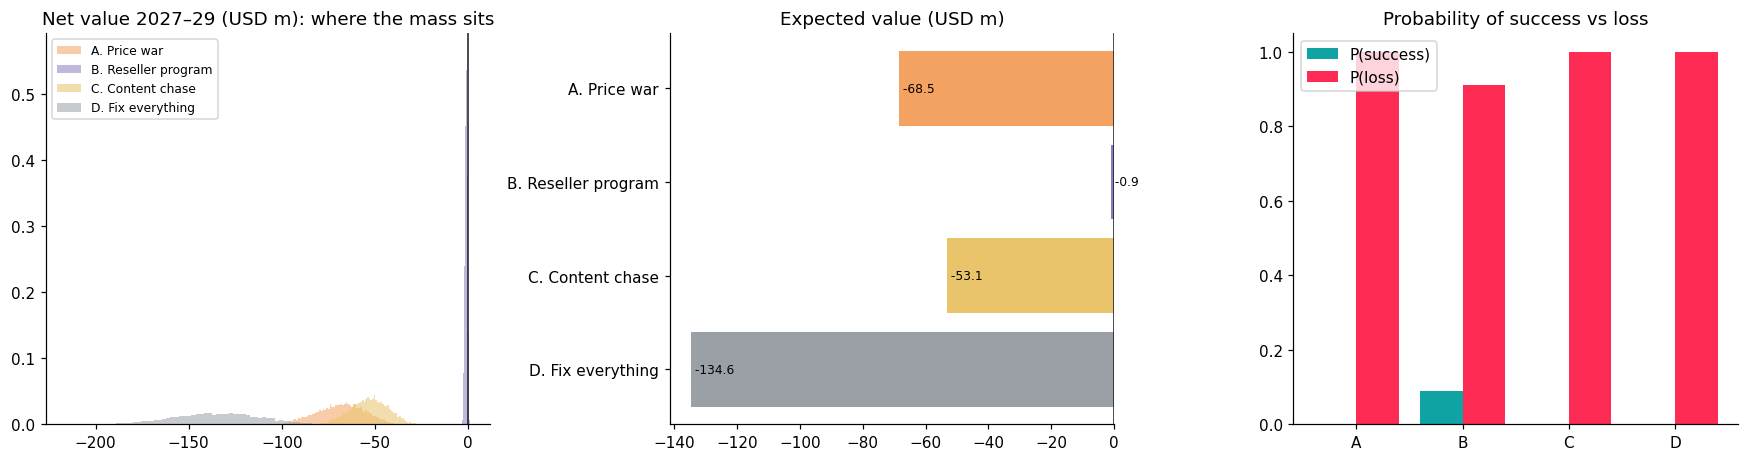

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ax = axes[0]
for k in ALTS:
    ax.hist(results[k].net_3y, bins=70, alpha=0.55, density=True, color=COLORS[k], label=k)
ax.axvline(0, color=DARK, lw=1); ax.legend(fontsize=8); ax.set_title("Net value 2027–29 (USD m): where the mass sits")

ax = axes[1]
ev = table.loc[ALTS, "EV net value 3y (USD m)"]
ax.barh(ALTS, ev, color=[COLORS[k] for k in ALTS]); ax.axvline(0, color=DARK, lw=1)
for i, v in enumerate(ev): ax.text(v, i, f" {v:,.1f}", va="center", fontsize=8)
ax.invert_yaxis(); ax.set_title("Expected value (USD m)")

ax = axes[2]
x = np.arange(len(ALTS))
ax.bar(x - 0.2, table.loc[ALTS, "P(success)"], 0.4, color=TEAL, label="P(success)")
ax.bar(x + 0.2, table.loc[ALTS, "P(loss)"], 0.4, color=PINK, label="P(loss)")
ax.set_xticks(x, [k.split(".")[0] for k in ALTS]); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title("Probability of success vs loss")
plt.tight_layout(); plt.show()

**Reading it.**
- **A (price war)** buys a lot of buyers, but pays vouchers on *every* Price-led order, and those buyers only repeat 26% of the time. Promo-driven lifts are mostly switching and pull-forward (Gupta, 1988), and they fade (Pauwels et al., 2002).
- **B (reseller)** has a decent chance of being mildly profitable, but it can never move the buyer count: resellers are only 1.1m buyers.
- **C** fights Competitor B where B is strongest (4.6 vs 3.0), and much of what it wins is simply taken from TikTok Shop.
- **D** fixes a real problem, but at a cost that the 7.1% margin cannot pay back.

# PART 2 — Our strategy: choose confidently, organize, restock reliably

In [8]:
show(table, highlight=["OURS"])

,EV net value 3y (USD m),Worst 5% (USD m),Best 5% (USD m),+Buyers 2027 (m),+Orders 2027 (m),+GMV 2027 (USD m),Cost 3y (USD m),ROI (net / cost),Cost per +buyer (USD),P(success),P(stretch: ≥0.5m buyers),P(loss)
A. Price war,-68.47,-89.90,-48.81,0.56,6.20,89.53,78.25,-88%,138.64,0%,0%,100%
B. Reseller program,-0.94,-2.13,0.18,0.03,0.90,70.41,1.87,-50%,62.26,9%,0%,91%
C. Content chase,-53.12,-70.03,-37.06,0.17,1.29,29.90,57.51,-92%,348.34,0%,0%,100%
D. Fix everything,-134.64,-173.56,-97.19,0.27,3.32,60.20,150.40,-90%,566.56,0%,0%,100%
OURS,11.00,-6.27,25.45,0.66,8.77,146.56,26.52,41%,40.42,86%,79%,14%
OURS + Reseller,9.96,-7.48,24.55,0.68,9.40,195.85,28.39,35%,41.92,84%,80%,16%


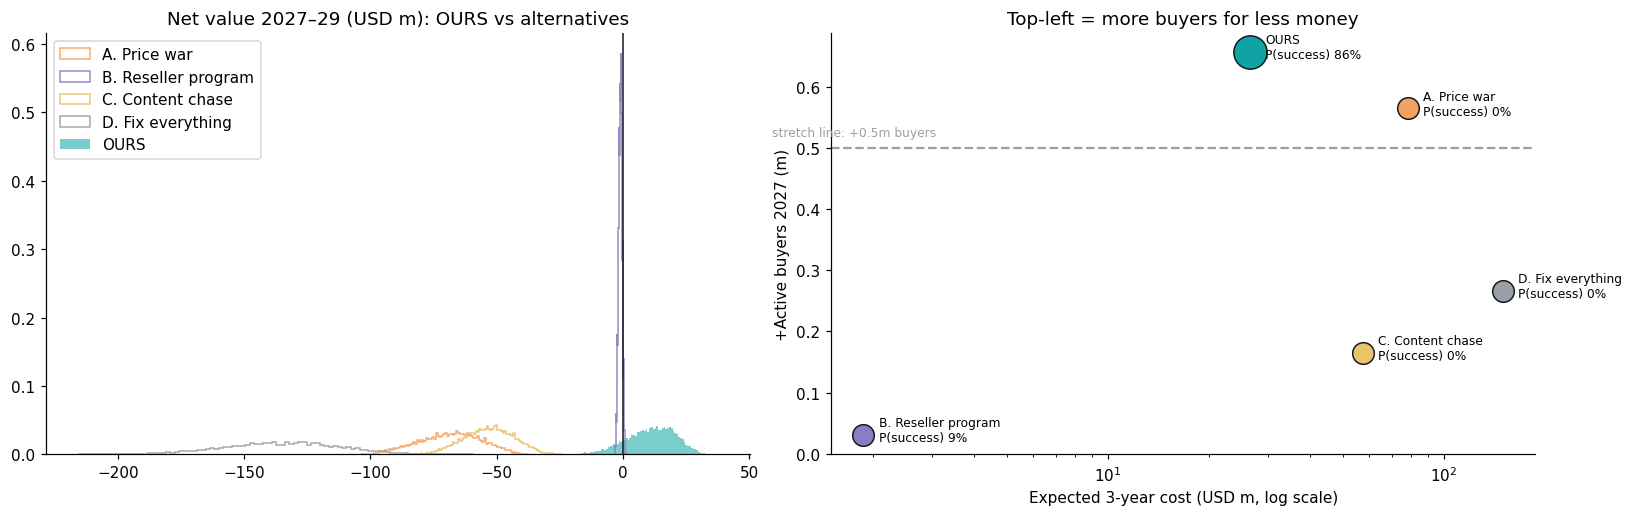

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
ax = axes[0]
for k in ALTS + ["OURS"]:
    ours = k == "OURS"
    ax.hist(results[k].net_3y, bins=90, density=True, histtype="stepfilled" if ours else "step",
            alpha=0.55 if ours else 0.9, lw=2.5 if ours else 1.3, color=COLORS[k], label=k)
ax.axvline(0, color=DARK, lw=1); ax.legend(); ax.set_title("Net value 2027–29 (USD m): OURS vs alternatives")

ax = axes[1]
for k in ALTS + ["OURS"]:
    r = table.loc[k]
    ax.scatter(r["Cost 3y (USD m)"], r["+Buyers 2027 (m)"], s=200 + max(r["EV net value 3y (USD m)"], 0) * 25,
               color=COLORS[k], edgecolor=DARK, zorder=3)
    ax.annotate(f"{k}\nP(success) {r['P(success)']:.0%}", (r["Cost 3y (USD m)"], r["+Buyers 2027 (m)"]),
                xytext=(10, -4), textcoords="offset points", fontsize=8)
ax.axhline(STRETCH, ls="--", color=GREY); ax.text(1, STRETCH + 0.02, "stretch line: +0.5m buyers", color=GREY, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Expected 3-year cost (USD m, log scale)"); ax.set_ylabel("+Active buyers 2027 (m)")
ax.set_title("Top-left = more buyers for less money")
plt.tight_layout(); plt.show()

### Which pillar does the work? (leave-one-out: EV of OURS minus EV of OURS without that lever)

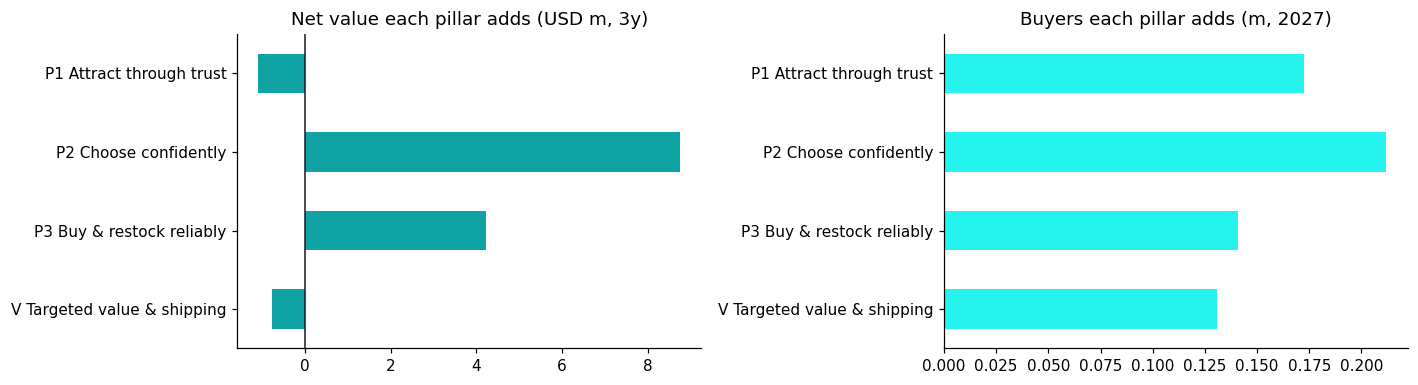

,Net value added 3y (USD m),+Buyers added 2027 (m),+Orders added 2027 (m),P(success) without it
P1 Attract through trust,-1.09,0.17,1.52,90%
P2 Choose confidently,8.76,0.21,2.52,64%
P3 Buy & restock reliably,4.22,0.14,3.03,80%
V Targeted value & shipping,-0.78,0.13,1.78,88%


In [10]:
base_ev = summarise(results["OURS"])
rows = {}
for lv in STRATEGIES["OURS"]["levers"]:
    s = summarise(simulate("OURS", drop=[lv]))
    rows[lv] = {"Net value added 3y (USD m)": base_ev["EV net value 3y (USD m)"] - s["EV net value 3y (USD m)"],
                "+Buyers added 2027 (m)": base_ev["+Buyers 2027 (m)"] - s["+Buyers 2027 (m)"],
                "+Orders added 2027 (m)": base_ev["+Orders 2027 (m)"] - s["+Orders 2027 (m)"],
                "P(success) without it": s["P(success)"]}
pillars = pd.DataFrame(rows).T

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
pillars["Net value added 3y (USD m)"].plot.barh(ax=axes[0], color=TEAL); axes[0].axvline(0, color=DARK, lw=1)
axes[0].set_title("Net value each pillar adds (USD m, 3y)"); axes[0].invert_yaxis()
pillars["+Buyers added 2027 (m)"].plot.barh(ax=axes[1], color=CYAN); axes[1].set_title("Buyers each pillar adds (m, 2027)")
axes[1].invert_yaxis()
plt.tight_layout(); plt.show()
pillars.style.format({"P(success) without it": "{:.0%}"} | {c: "{:,.2f}" for c in pillars.columns[:3]})

### Where do the extra buyers come from? (2027, by archetype)

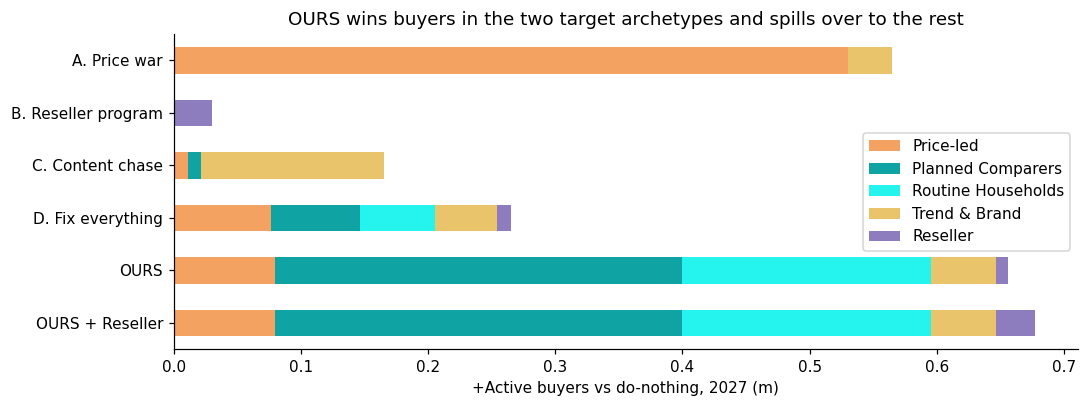

In [11]:
seg_cols = [f"inc_buyers::{s}" for s in SEGS]
by_seg = pd.DataFrame({k: results[k][seg_cols].mean().values for k in STRATEGIES}, index=SEGS).T
ax = by_seg.loc[ALTS + ["OURS", "OURS + Reseller"]].plot.barh(stacked=True, figsize=(10, 3.8),
        color=["#F4A261", TEAL, CYAN, "#E9C46A", "#8E7DBE"])
ax.invert_yaxis(); ax.set_xlabel("+Active buyers vs do-nothing, 2027 (m)")
ax.set_title("OURS wins buyers in the two target archetypes and spills over to the rest")
plt.tight_layout(); plt.show()

# PART 3 — Should we bolt a reseller program onto our strategy?

`OURS` and `OURS + Reseller` share the **exact same random worlds and the same draws for our four levers** (common random numbers). Any difference is therefore caused **only** by the reseller program.

In [12]:
o, orr = results["OURS"], results["OURS + Reseller"]
cmp_ = table.loc[["OURS", "OURS + Reseller"]].copy()
cmp_.loc["Difference (reseller add-on)"] = cmp_.loc["OURS + Reseller"] - cmp_.loc["OURS"]
show(cmp_, highlight=["Difference (reseller add-on)"])

,EV net value 3y (USD m),Worst 5% (USD m),Best 5% (USD m),+Buyers 2027 (m),+Orders 2027 (m),+GMV 2027 (USD m),Cost 3y (USD m),ROI (net / cost),Cost per +buyer (USD),P(success),P(stretch: ≥0.5m buyers),P(loss)
OURS,11.00,-6.27,25.45,0.66,8.77,146.56,26.52,41%,40.42,86%,79%,14%
OURS + Reseller,9.96,-7.48,24.55,0.68,9.40,195.85,28.39,35%,41.92,84%,80%,16%
Difference (reseller add-on),-1.04,-1.21,-0.90,0.02,0.63,49.29,1.87,-6%,1.51,-2%,0%,2%


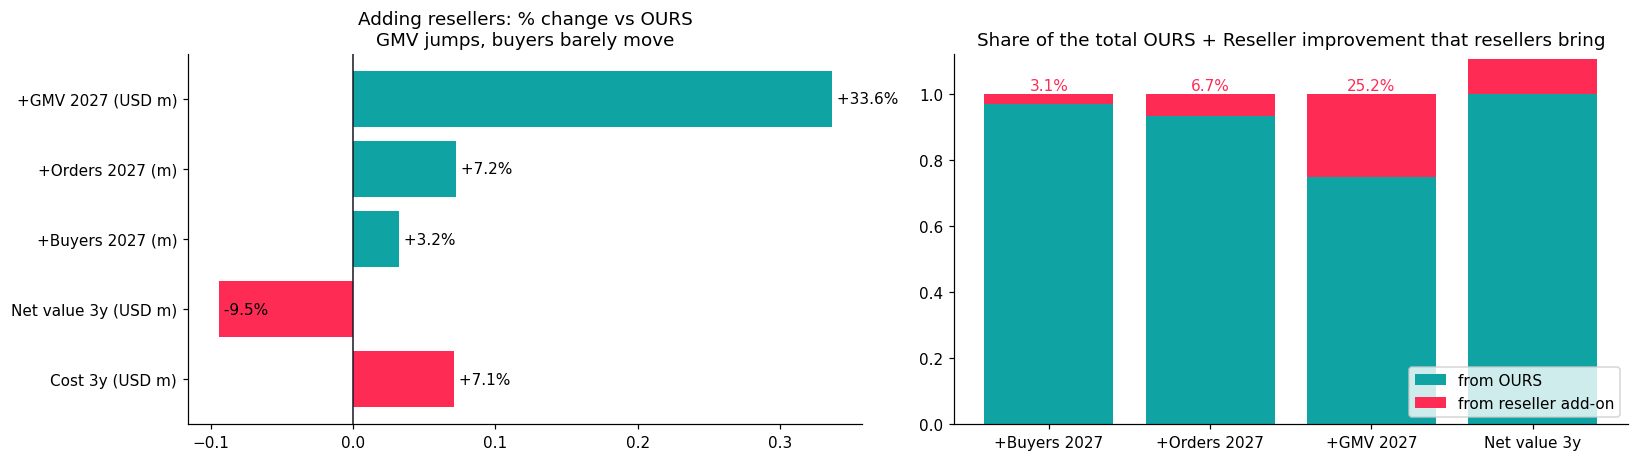

Resellers: 1.11m buyers (4.1%), 645m GMV, 3.8% margin, 68% orders on promo
Add-on adds 21k buyers = 0.7% of the 3m lost buyers, for 1.9m extra cost -> $89 per extra buyer vs $40 for OURS
Net value added: -1.04m over 3y | P(add-on loses money) 93%


,orders,gmv,contribution,coverage,abuse_pp,contribution Δ USD m,abuse leak USD m,net USD m (before programme cost)
2% qty price >$125,0.05,0.08,0.01,1.00,0.00,0.25,0.00,0.25
5% qty price >$125,0.11,0.17,-0.06,1.00,0.00,-1.47,0.00,-1.47
$3.125 shipping >$93.75,0.07,0.09,0.02,1.00,0.00,0.49,0.00,0.49
$6.25 voucher >$187.50,0.09,0.13,-0.01,1.00,0.02,-0.25,3.87,-4.12
Seller-funded 3% bulk,0.06,0.10,0.05,0.37,0.00,0.45,0.00,0.45


In [13]:
d = pd.DataFrame({
    "+GMV 2027 (USD m)": [o.inc_gmv_m.mean(), orr.inc_gmv_m.mean()],
    "+Orders 2027 (m)": [o.inc_orders.mean(), orr.inc_orders.mean()],
    "+Buyers 2027 (m)": [o.inc_buyers.mean(), orr.inc_buyers.mean()],
    "Net value 3y (USD m)": [o.net_3y.mean(), orr.net_3y.mean()],
    "Cost 3y (USD m)": [o.cost_3y.mean(), orr.cost_3y.mean()],
}, index=["OURS", "OURS + Reseller"])
pct = (d.loc["OURS + Reseller"] / d.loc["OURS"] - 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
ax = axes[0]
ax.barh(pct.index, pct.values, color=[TEAL if (v > 0) ^ (k == "Cost 3y (USD m)") else PINK for k, v in pct.items()])
for i, v in enumerate(pct.values): ax.text(v, i, f" {v:+.1%}", va="center")
ax.axvline(0, color=DARK, lw=1); ax.invert_yaxis()
ax.set_title("Adding resellers: % change vs OURS\nGMV jumps, buyers barely move")

ax = axes[1]
add = {"+Buyers 2027": ((orr.inc_buyers - o.inc_buyers).mean(), orr.inc_buyers.mean()),
       "+Orders 2027": ((orr.inc_orders - o.inc_orders).mean(), orr.inc_orders.mean()),
       "+GMV 2027": ((orr.inc_gmv_m - o.inc_gmv_m).mean(), orr.inc_gmv_m.mean()),
       "Net value 3y": ((orr.net_3y - o.net_3y).mean(), orr.net_3y.mean())}
share = pd.Series({k: a / tot for k, (a, tot) in add.items()})
ax.bar(share.index, 1 - share.values, color=TEAL, label="from OURS")
ax.bar(share.index, share.values, bottom=1 - share.values, color=PINK, label="from reseller add-on")
for i, v in enumerate(share.values): ax.text(i, 1.01, f"{v:.1%}", ha="center", color=PINK)
ax.set_ylim(0, 1.12); ax.legend(loc="lower right")
ax.set_title("Share of the total OURS + Reseller improvement that resellers bring")
plt.tight_layout(); plt.show()

r = seg.loc["Reseller"]
print(f"Resellers: {r.buyers_m:.2f}m buyers ({r.buyer_share:.1%}), {r.gmv_m:.0f}m GMV, {r.margin:.1%} margin, {r.promo_sens:.0%} orders on promo")
add_b = (orr.inc_buyers - o.inc_buyers).mean()
add_c = d.loc["OURS + Reseller", "Cost 3y (USD m)"] - d.loc["OURS", "Cost 3y (USD m)"]
print(f"Add-on adds {add_b*1000:,.0f}k buyers = {add_b/3:.1%} of the 3m lost buyers, for {add_c:.1f}m extra cost "
      f"-> ${add_c/add_b:,.0f} per extra buyer vs ${table.loc['OURS','Cost per +buyer (USD)']:,.0f} for OURS")
print(f"Net value added: {(orr.net_3y - o.net_3y).mean():+.2f}m over 3y | P(add-on loses money) {((orr.net_3y - o.net_3y) < 0).mean():.0%}")

rt = RESELLER_TESTS.copy()
rt["contribution Δ USD m"] = rt.contribution * rt.coverage * r.contribution_m
rt["abuse leak USD m"] = rt.abuse_pp * r.gmv_m * ABUSE_LEAK
rt["net USD m (before programme cost)"] = rt["contribution Δ USD m"] - rt["abuse leak USD m"]
rt

**Verdict.** We gave resellers their *best possible* program: only the three tested levers that grew contribution, with no abuse-prone voucher. It can pay off, so its P(success) is not zero. But look at **what the increase buys**: a big jump in GMV, a near-zero change in active buyers (resellers are only 1.1m buyers at a 3.8% margin), and a cost per extra buyer many times higher than OURS. The case mandate is to **restore active buyers and order frequency**, not GMV. **Serve resellers through business as usual**; they still benefit from the P2 search/compare and P3 inventory spill-over.

# PART 4 — Law of large numbers: is the improvement real?

The Monte Carlo average converges to the true expected value as the number of simulations *N* grows. Its error shrinks like **σ/√N** (Metropolis & Ulam, 1949). With 10 runs the average is noisy enough to tell the wrong story. At 10,000 runs it settles.

**4a. Running average** of one long simulation, with 95% confidence bands.

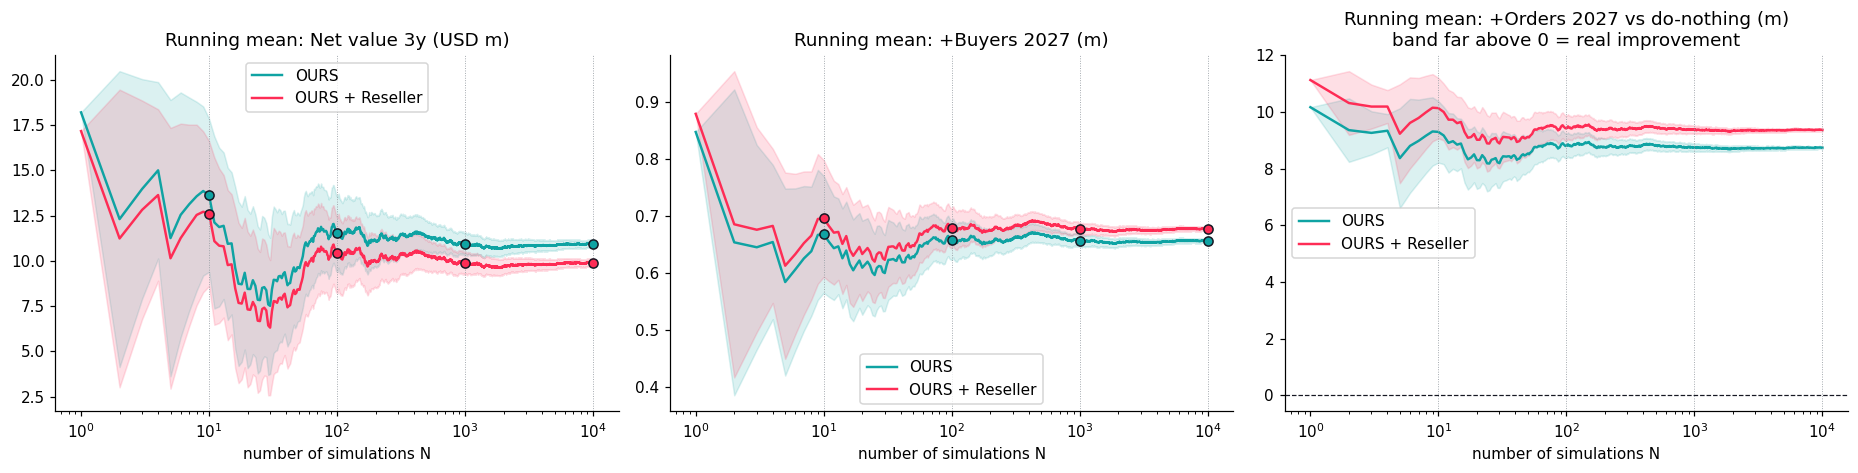

,OURS mean net 3y,OURS+R mean net 3y,OURS +buyers (m),OURS +buyers 95% CI ±,Reseller add-on net (USD m),Reseller add-on +buyers (m),OURS P(success),OURS+R P(success)
N simulations,,,,,,,,
10,13.63,12.62,0.67,0.11,-1.01,0.03,90%,90%
100,11.55,10.41,0.66,0.03,-1.14,0.02,83%,80%
1000,10.92,9.86,0.66,0.01,-1.06,0.02,85%,83%
10000,10.93,9.88,0.66,0.00,-1.05,0.02,86%,84%


In [14]:
N_MAX = 10_000
CHECK = [10, 100, 1_000, 10_000]
o_long = simulate("OURS", n=N_MAX, seed=11)
r_long = simulate("OURS + Reseller", n=N_MAX, seed=11)   # same worlds -> paired comparison

def running(x):
    x = np.asarray(x); k = np.arange(1, len(x) + 1)
    mean = np.cumsum(x) / k
    sd = np.sqrt(np.maximum(np.cumsum(x**2) / k - mean**2, 0))
    return k, mean, 1.96 * sd / np.sqrt(k)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, metric, title in [(axes[0], "net_3y", "Net value 3y (USD m)"), (axes[1], "inc_buyers", "+Buyers 2027 (m)")]:
    for df, name in [(o_long, "OURS"), (r_long, "OURS + Reseller")]:
        k, m, ci = running(df[metric])
        ax.plot(k, m, color=COLORS[name], lw=1.6, label=name)
        ax.fill_between(k, m - ci, m + ci, color=COLORS[name], alpha=0.15)
        for c in CHECK: ax.scatter(c, m[c - 1], color=COLORS[name], edgecolor=DARK, zorder=4)
    ax.set_xscale("log"); ax.set_xlabel("number of simulations N"); ax.set_title(f"Running mean: {title}")
    for c in CHECK: ax.axvline(c, color=GREY, lw=0.6, ls=":")
    ax.legend()

ax = axes[2]
for df, name in [(o_long, "OURS"), (r_long, "OURS + Reseller")]:
    k, m, ci = running(df.inc_orders)
    ax.plot(k, m, color=COLORS[name], lw=1.6, label=name)
    ax.fill_between(k, m - ci, m + ci, color=COLORS[name], alpha=0.15)
ax.axhline(0, color=DARK, lw=0.8, ls="--"); ax.set_xscale("log"); ax.legend()
for c in CHECK: ax.axvline(c, color=GREY, lw=0.6, ls=":")
ax.set_title("Running mean: +Orders 2027 vs do-nothing (m)\nband far above 0 = real improvement")
ax.set_xlabel("number of simulations N")
plt.tight_layout(); plt.show()

conv = pd.DataFrame({N: {
    "OURS mean net 3y": o_long.net_3y[:N].mean(),
    "OURS+R mean net 3y": r_long.net_3y[:N].mean(),
    "OURS +buyers (m)": o_long.inc_buyers[:N].mean(),
    "OURS +buyers 95% CI ±": 1.96 * o_long.inc_buyers[:N].std() / np.sqrt(N),
    "Reseller add-on net (USD m)": (r_long.net_3y[:N] - o_long.net_3y[:N]).mean(),
    "Reseller add-on +buyers (m)": (r_long.inc_buyers[:N] - o_long.inc_buyers[:N]).mean(),
    "OURS P(success)": ((o_long.net_3y[:N] > 0) & (o_long.inc_buyers[:N] > 0)).mean(),
    "OURS+R P(success)": ((r_long.net_3y[:N] > 0) & (r_long.inc_buyers[:N] > 0)).mean(),
} for N in CHECK}).T
conv.index.name = "N simulations"
conv.style.format("{:,.2f}").format("{:.0%}", subset=["OURS P(success)", "OURS+R P(success)"])

**4b. Repeat the whole experiment 200 times** at N = 10, 100, 1,000, and 10,000. Each box shows how much the *average result* moves from one experiment to the next. The strategies use **independent** random worlds here. At N = 10 a single run can show almost anything: a loss, or a huge win. As N grows, every run lands on the same answer. OURS clearly creates value, and the reseller add-on barely shifts it.

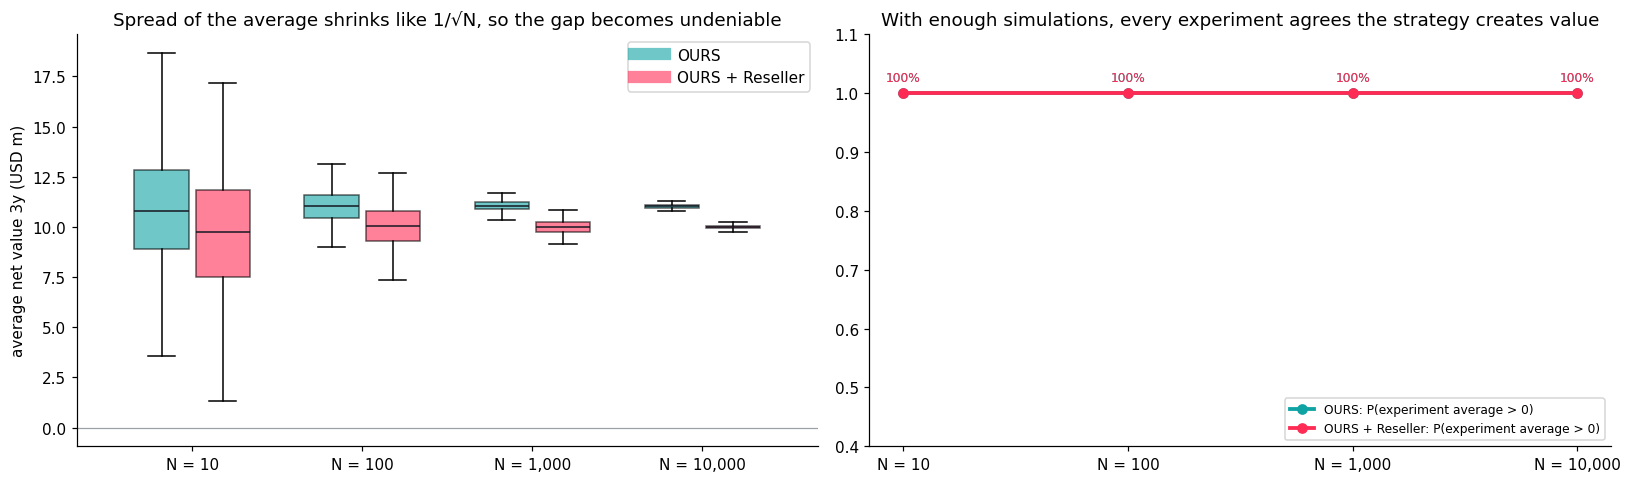

,std of avg: OURS,std of avg: OURS+R,theory σ/√N (OURS)
N,,,
10,2.92,3.19,3.08
100,0.94,1.01,0.98
1000,0.31,0.33,0.31
10000,0.10,0.10,0.10


In [15]:
REPS = 200
rep = {name: {N: np.array([simulate(name, n=N, seed=1000 + i + (0 if name == "OURS" else 500_000)).net_3y.mean()
                           for i in range(REPS)]) for N in CHECK} for name in ["OURS", "OURS + Reseller"]}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ax = axes[0]
pos = np.arange(len(CHECK))
for j, (name, off) in enumerate([("OURS", -0.18), ("OURS + Reseller", 0.18)]):
    bp = ax.boxplot([rep[name][N] for N in CHECK], positions=pos + off, widths=0.32, patch_artist=True,
                    showfliers=False, medianprops=dict(color=DARK))
    for b in bp["boxes"]: b.set_facecolor(COLORS[name]); b.set_alpha(0.6)
    ax.plot([], [], color=COLORS[name], lw=8, alpha=0.6, label=name)
ax.set_xticks(pos, [f"N = {N:,}" for N in CHECK]); ax.axhline(0, color=GREY, lw=0.8)
ax.set_ylabel("average net value 3y (USD m)"); ax.legend()
ax.set_title("Spread of the average shrinks like 1/√N, so the gap becomes undeniable")

ax = axes[1]
sd = pd.DataFrame({name: [rep[name][N].std() for N in CHECK] for name in rep}, index=CHECK)
for name in rep:
    pos_share = [np.mean(rep[name][N] > 0) for N in CHECK]
    ax.plot(pos, pos_share, marker="o", color=COLORS[name], lw=2.5, label=f"{name}: P(experiment average > 0)")
    for i, w in enumerate(pos_share): ax.text(i, w + 0.02, f"{w:.0%}", ha="center", color=COLORS[name], fontsize=8)
ax.set_ylim(0.4, 1.1); ax.set_xticks(pos, [f"N = {N:,}" for N in CHECK]); ax.legend(loc="lower right", fontsize=8)
ax.set_title("With enough simulations, every experiment agrees the strategy creates value")
plt.tight_layout(); plt.show()

sd["theory σ/√N (OURS)"] = o_long.net_3y.std() / np.sqrt(sd.index)
sd.index.name = "N"; sd.columns = ["std of avg: OURS", "std of avg: OURS+R", "theory σ/√N (OURS)"]
sd

**4c. All strategies converge, and the ranking is stable once N is large.**

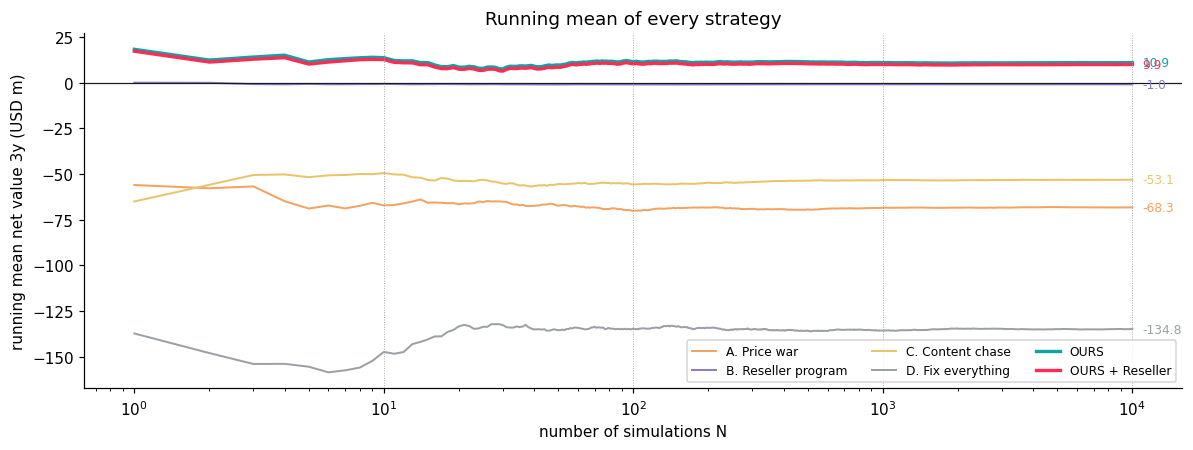

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for k in STRATEGIES:
    kk, m, _ = running(simulate(k, n=N_MAX, seed=11).net_3y)
    ax.plot(kk, m, color=COLORS[k], lw=2.2 if k.startswith("OURS") else 1.3, label=k)
    ax.text(N_MAX * 1.1, m[-1], f"{m[-1]:,.1f}", color=COLORS[k], va="center", fontsize=8)
ax.set_xscale("log"); ax.axhline(0, color=DARK, lw=0.8)
for c in CHECK: ax.axvline(c, color=GREY, lw=0.6, ls=":")
ax.set_xlabel("number of simulations N"); ax.set_ylabel("running mean net value 3y (USD m)")
ax.legend(fontsize=8, ncol=3); ax.set_title("Running mean of every strategy")
plt.tight_layout(); plt.show()

# PART 5 — Recovery path 2027–2029

The do-nothing line assumes the 2025→2026 decline (−6.9% buyers, −3.3% orders per buyer) continues each year. Shaded areas show the middle 80% of simulated worlds.

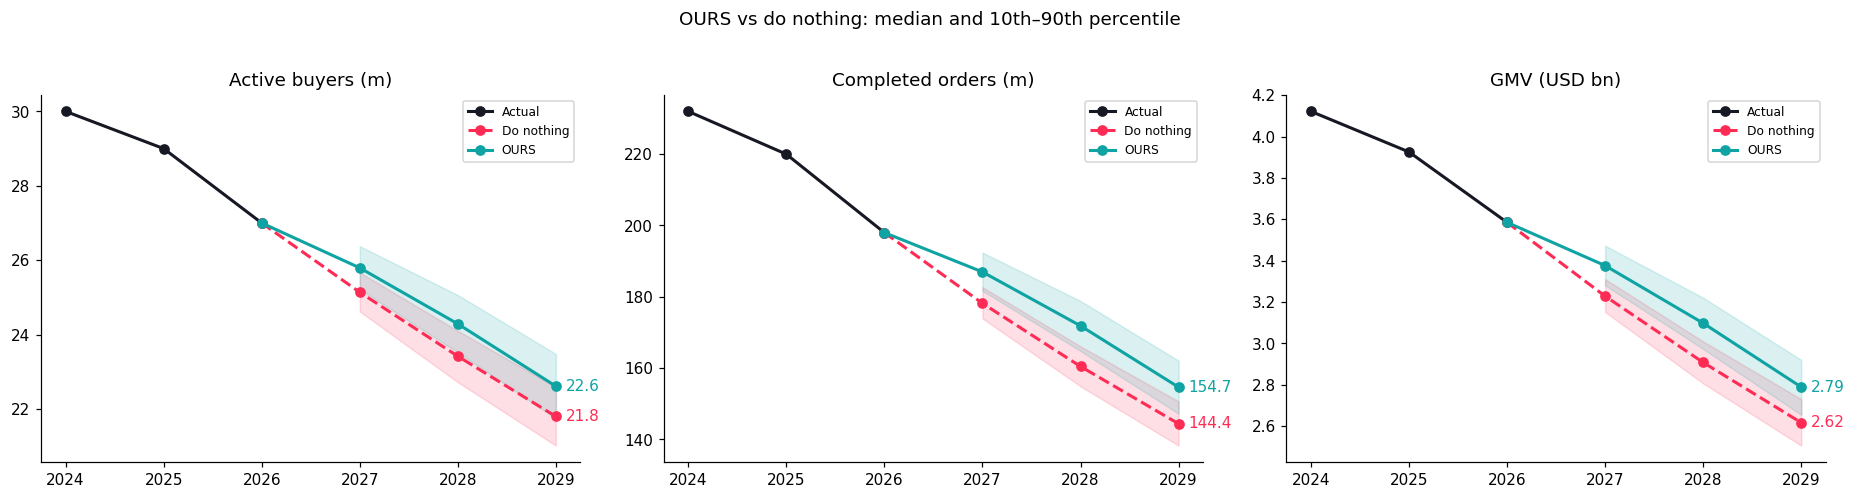

,Lost buyers recovered 2027 (of 3m),Lost orders recovered 2027 (of 34m),Buyers 2029 vs do-nothing (m),Orders 2029 vs do-nothing (m),Decline slowed 2027 (buyers)
OURS,22%,26%,0.81,10.22,35%
OURS + Reseller,23%,28%,0.84,10.95,36%
A. Price war,19%,18%,0.28,2.79,30%
B. Reseller program,1%,3%,0.02,0.59,2%
C. Content chase,6%,4%,0.13,0.95,9%
D. Fix everything,9%,10%,0.38,4.51,14%


In [17]:
def band(df, prefix):
    v = np.column_stack([df[f"{prefix}_{y}"] for y in YEARS])
    return np.percentile(v, 10, axis=0), np.median(v, axis=0), np.percentile(v, 90, axis=0)

o = results["OURS"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (metric, hcol, unit) in zip(axes, [("buyers", "active_buyers_m", "Active buyers (m)"),
                                           ("orders", "orders_m", "Completed orders (m)"),
                                           ("gmv", "gmv_bn", "GMV (USD bn)")]):
    h = hist[hcol]
    ax.plot(h.index, h.values, color=DARK, marker="o", lw=2, label="Actual")
    for pre, name, col in [("base_" + metric, "Do nothing", PINK), (metric, "OURS", TEAL)]:
        lo, med, hi = band(o, pre)
        xs = [2026] + YEARS
        ax.plot(xs, [h.loc[2026]] + list(med), color=col, marker="o", lw=2, label=name, ls="--" if name == "Do nothing" else "-")
        ax.fill_between(YEARS, lo, hi, color=col, alpha=0.15)
        ax.text(2029.1, med[-1], f"{med[-1]:,.1f}" if metric != "gmv" else f"{med[-1]:.2f}", color=col, va="center")
    ax.set_title(unit); ax.set_xticks(list(h.index) + YEARS); ax.legend(fontsize=8)
plt.suptitle("OURS vs do nothing: median and 10th–90th percentile", y=1.02)
plt.tight_layout(); plt.show()

rec = {}
for k in ["OURS", "OURS + Reseller"] + ALTS:
    df = results[k]
    rec[k] = {
        "Lost buyers recovered 2027 (of 3m)": df.inc_buyers.mean() / 3,
        "Lost orders recovered 2027 (of 34m)": df.inc_orders.mean() / 34,
        "Buyers 2029 vs do-nothing (m)": (df.buyers_2029 - df.base_buyers_2029).mean(),
        "Orders 2029 vs do-nothing (m)": (df.orders_2029 - df.base_orders_2029).mean(),
        "Decline slowed 2027 (buyers)": 1 - (27 - df.buyers_2027.mean()) / (27 - df.base_buyers_2027.mean()),
    }
rec = pd.DataFrame(rec).T
rec.style.format({c: "{:.0%}" for c in rec.columns if "recovered" in c or "slowed" in c} |
                 {c: "{:,.2f}" for c in rec.columns if "vs" in c})

**How to say it in the deck.** OURS does not magically return to 30m buyers in one year, and nothing in the case data supports that claim. It **cuts the 2027 buyer decline sharply, the gap to do-nothing widens every year** because capabilities don't fade, and it is the **only** strategy that does this while paying for itself.

# PART 6 — Stress tests
### 6a. Tornado: the pessimistic end of each pillar's assumptions

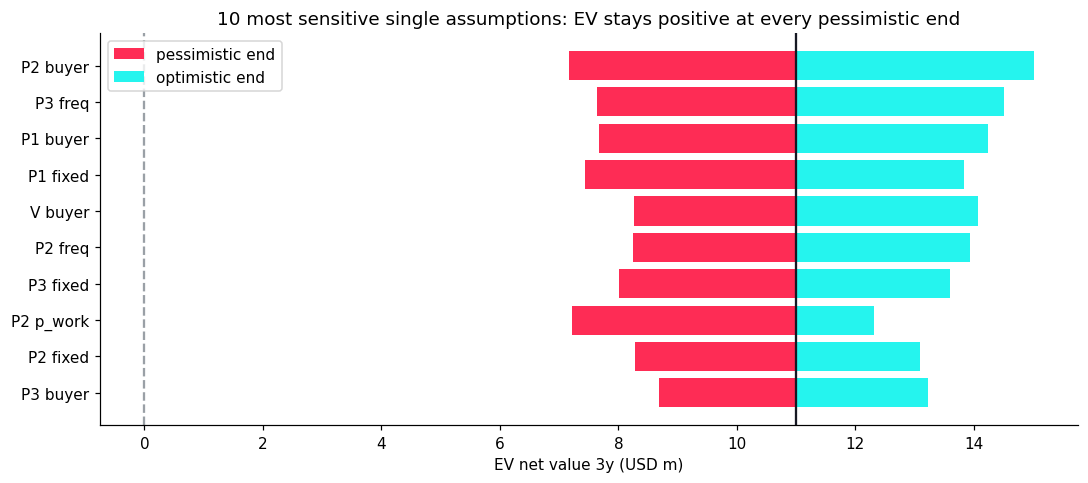

In [18]:
tests = []
for lv in STRATEGIES["OURS"]["levers"]:
    L = LEVERS[lv]
    for p in ["buyer", "freq", "fixed", "p_work"]:
        if p == "p_work":
            bad, good = {"p_work": max(L[p] - 0.25, 0.3)}, {"p_work": min(L[p] + 0.1, 0.99)}
        else:
            lo, _, hi = L[p]
            bad, good = ({p: (hi, hi, hi)}, {p: (lo, lo, lo)}) if p == "fixed" else ({p: (lo, lo, lo)}, {p: (hi, hi, hi)})
        e_bad = simulate("OURS", n=4000, lever_overrides={lv: bad}).net_3y.mean()
        e_good = simulate("OURS", n=4000, lever_overrides={lv: good}).net_3y.mean()
        tests.append((f"{lv.split()[0]} {p}", e_bad, e_good))
tor = pd.DataFrame(tests, columns=["assumption", "pessimistic", "optimistic"])
tor["range"] = tor.optimistic - tor.pessimistic
tor = tor.sort_values("range").tail(10)
ev0 = table.loc["OURS", "EV net value 3y (USD m)"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(tor.assumption, tor.pessimistic - ev0, left=ev0, color=PINK, label="pessimistic end")
ax.barh(tor.assumption, tor.optimistic - ev0, left=ev0, color=CYAN, label="optimistic end")
ax.axvline(ev0, color=DARK); ax.axvline(0, color=GREY, ls="--")
ax.set_xlabel("EV net value 3y (USD m)"); ax.legend()
ax.set_title("10 most sensitive single assumptions: EV stays positive at every pessimistic end")
plt.tight_layout(); plt.show()

### 6b. Break-even: what if every effect turns out smaller than assumed?

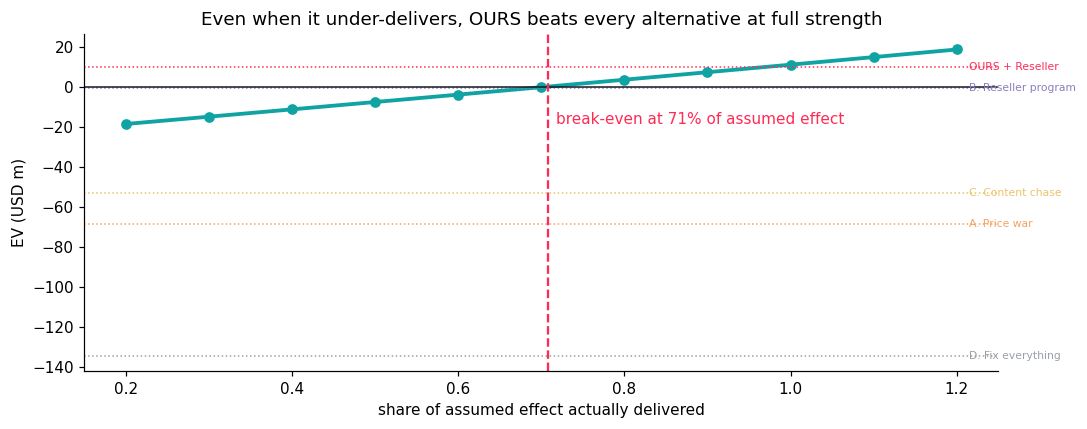

,EV net value 3y (USD m),+Buyers 2027 (m),P(success),P(loss)
0.200000,-18.69,0.13,0%,100%
0.300000,-15.05,0.20,0%,100%
0.400000,-11.39,0.26,0%,100%
0.500000,-7.71,0.33,7%,93%
0.600000,-4.01,0.39,28%,72%
0.700000,-0.30,0.46,52%,48%
0.800000,3.43,0.52,68%,32%
0.900000,7.18,0.59,79%,21%
1.000000,10.95,0.66,86%,14%
1.100000,14.74,0.72,90%,10%


In [19]:
scales = np.round(np.arange(0.2, 1.21, 0.1), 2)
stress = pd.DataFrame({s: summarise(simulate("OURS", n=5000, effect_scale=s)) for s in scales}).T
be = np.interp(0, stress["EV net value 3y (USD m)"], stress.index)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stress.index, stress["EV net value 3y (USD m)"], marker="o", color=TEAL, lw=2.5, label="OURS")
for k in ALTS + ["OURS + Reseller"]:
    v = table.loc[k, "EV net value 3y (USD m)"]
    ax.axhline(v, ls=":", lw=1, color=COLORS[k]); ax.text(1.215, v, k, fontsize=7, va="center", color=COLORS[k])
ax.axhline(0, color=DARK, lw=1); ax.axvline(be, color=PINK, ls="--")
ax.text(be + 0.01, stress["EV net value 3y (USD m)"].min(), f"break-even at {be:.0%} of assumed effect", color=PINK)
ax.set_xlabel("share of assumed effect actually delivered"); ax.set_ylabel("EV (USD m)")
ax.set_title("Even when it under-delivers, OURS beats every alternative at full strength")
plt.tight_layout(); plt.show()
stress[["EV net value 3y (USD m)", "+Buyers 2027 (m)", "P(success)", "P(loss)"]].style.format(
    {"EV net value 3y (USD m)": "{:,.2f}", "+Buyers 2027 (m)": "{:,.2f}", "P(success)": "{:.0%}", "P(loss)": "{:.0%}"})

## Headline numbers for the deck

In [20]:
o_, r_ = table.loc["OURS"], table.loc["OURS + Reseller"]
a = table.loc[ALTS]
best = a["EV net value 3y (USD m)"].idxmax()
print(f"OURS            : EV {o_['EV net value 3y (USD m)']:+.1f}m | +{o_['+Buyers 2027 (m)']:.2f}m buyers "
      f"({o_['+Buyers 2027 (m)']/3:.0%} of lost buyers) | +{o_['+Orders 2027 (m)']:.1f}m orders | "
      f"P(success) {o_['P(success)']:.0%} | P(loss) {o_['P(loss)']:.0%} | ROI {o_['ROI (net / cost)']:.0%}")
print(f"OURS + Reseller : EV {r_['EV net value 3y (USD m)']:+.1f}m | +{r_['+Buyers 2027 (m)']:.2f}m buyers | "
      f"P(success) {r_['P(success)']:.0%} | P(loss) {r_['P(loss)']:.0%}")
print(f"Best alternative: {best} EV {a.loc[best,'EV net value 3y (USD m)']:+.1f}m, P(success) {a.loc[best,'P(success)']:.0%}")
print(f"Cost per extra buyer: OURS ${o_['Cost per +buyer (USD)']:.0f} vs alternatives "
      f"${a['Cost per +buyer (USD)'].min():.0f}–${a['Cost per +buyer (USD)'].max():,.0f}")
print(f"Break-even: OURS still pays if only {be:.0%} of the assumed effect shows up")
print(f"Convergence: at N=10,000 OURS adds {conv.loc[10000,'OURS +buyers (m)']:.3f}m ± "
      f"{conv.loc[10000,'OURS +buyers 95% CI ±']:.3f}m buyers (95% CI); reseller add-on changes net value by "
      f"{conv.loc[10000,'Reseller add-on net (USD m)']:+.2f}m and buyers by {conv.loc[10000,'Reseller add-on +buyers (m)']*1000:+.0f}k")

OURS            : EV +11.0m | +0.66m buyers (22% of lost buyers) | +8.8m orders | P(success) 86% | P(loss) 14% | ROI 41%
OURS + Reseller : EV +10.0m | +0.68m buyers | P(success) 84% | P(loss) 16%
Best alternative: B. Reseller program EV -0.9m, P(success) 9%
Cost per extra buyer: OURS $40 vs alternatives $62–$567
Break-even: OURS still pays if only 71% of the assumed effect shows up
Convergence: at N=10,000 OURS adds 0.657m ± 0.003m buyers (95% CI); reseller add-on changes net value by -1.05m and buyers by +21k


## Assumptions and limitations (put these in the appendix)

- Case data are fictional and used as given. Archetype buyers = rounded share × 27.0m; archetype GMV = Exhibit 3A orders × AOV (3.587bn vs 3.585bn, within the case tolerance).
- **Effect sizes, success probabilities, costs, ramp, and decay are assumptions.** The case gives no adoption, conversion, or cost data (rules 1.3 and 6.2). They are anchored to exhibit pain points and to published research, and they are stress-tested in Part 6.
- The model works at archetype level. The 14m and 25m lead-journey cells motivate the weights, but cell-level GMV and margin are not allocated (case rule).
- The do-nothing world assumes the 2025→2026 decline continues each year (a pessimistic baseline). Results are always reported **relative to it**.
- The reseller program is modelled at its best design: the three positive-contribution tests stacked, with a 30% overlap haircut and ±50% noise. The abuse on the voucher test (25% of extra attempts leaking value) is shown only in the test table.
- TikTok Shop cannibalization is valued at the 7.1% portfolio margin (group view).
- This is a **comparative scenario model**, not a forecast of 2027 results.

## References

1. Hertz, D. B. (1964). Risk Analysis in Capital Investment. *Harvard Business Review*, 42(1), 95–106. *(Monte Carlo for strategic decisions under uncertainty)*
2. Metropolis, N., & Ulam, S. (1949). The Monte Carlo Method. *Journal of the American Statistical Association*, 44(247), 335–341. *(convergence of simulated averages)*
3. Gupta, S. (1988). Impact of Sales Promotions on When, What, and How Much to Buy. *Journal of Marketing Research*, 25(4), 342–355. *(most promo lift is brand switching, not new demand)*
4. Mela, C. F., Gupta, S., & Lehmann, D. R. (1997). The Long-Term Impact of Promotion and Advertising on Consumer Brand Choice. *Journal of Marketing Research*, 34(2), 248–261. *(promotions increase price/promo sensitivity)*
5. Pauwels, K., Hanssens, D. M., & Siddarth, S. (2002). The Long-Term Effects of Price Promotions on Category Incidence, Brand Choice, and Purchase Quantity. *Journal of Marketing Research*, 39(4), 421–439. *(promotion effects rarely persist)*
6. Häubl, G., & Trifts, V. (2000). Consumer Decision Making in Online Shopping Environments: The Effects of Interactive Decision Aids. *Marketing Science*, 19(1), 4–21. *(comparison matrices reduce search effort, improve decision quality)*
7. Iyengar, S. S., & Lepper, M. R. (2000). When Choice Is Demotivating. *Journal of Personality and Social Psychology*, 79(6), 995–1006. *(too many options lower purchase)*
8. Corsten, D., & Gruen, T. (2003). Desperately Seeking Shelf Availability. *International Journal of Retail & Distribution Management*, 31(12), 605–617. *(shopper responses to stock-outs)*
9. Reichheld, F. F., & Sasser, W. E. (1990). Zero Defections: Quality Comes to Services. *Harvard Business Review*, 68(5), 105–111. *(retention drives profitability)*
10. Gupta, S., Lehmann, D. R., & Stuart, J. A. (2004). Valuing Customers. *Journal of Marketing Research*, 41(1), 7–18. *(retention is a stronger value lever than margin or acquisition cost)*

*Literature supports the **direction** of each assumption (promos leak and fade; comparison aids and availability raise conversion and repeat). It does not supply case-specific effect sizes.*